# 4. 발주

| 세부 기능 | 판매자 질문 예시 | 도구 |
| --- | --- | --- |
| 4-1 주간 수요 예측 | "다음 4주 몇 개 팔릴까?" | `demand_forecast`, `plot_forecast` |
| 4-2 이벤트 반영 + 과거 시점 재현 | "다음 달 어머니날 반영해줘" | `demand_forecast(as_of=…)` |
| 4-3 발주량 계산 + 품절 위험 조정 | "재고 20개, 입고 2주. 얼마나 주문해?" | `reorder_quantity` |
| 4-4 발주 우선순위 | "뭐부터 주문해?" | `reorder_priority` |
| 4-5 이벤트 배수 표 | "어머니날엔 몇 배 팔려?" | `event_multiples` (전처리 2판) |

**예측 방법**: 최근 주간 판매의 지수가중평균(8주) × 이벤트 배수. 예측 실험에서 검증 기간 성능이 가장 좋았던 방법이에요. 이벤트 배수는 **지난해 같은 이벤트** 값을 써서 미래 정보가 섞이지 않아요.

**한계**: 상품의 59%가 딱 한 번 팔려서 상품 단위 예측은 어렵고, 판매자 × 카테고리 × 주 단위로 예측해요. 입고 기간과 현재 재고는 데이터에 없어서 판매자가 입력해요.

**실행법 (Colab)**: GitHub 저장소(jc020230/BDA)에서 이 노트북을 Colab으로 열고 위에서부터 실행하면 돼요. 첫 셀이 저장소를 자동으로 내려받아서 `seller_tools.py`와 `preprocessing/` 폴더의 데이터를 찾아요. 노트북끼리는 서로 독립이라 아무거나 먼저 열어도 돼요.

**아래 "챗봇이 이렇게 말할 수 있어요"** 문장은 도구 결과 숫자로 자동으로 만든 예시예요. 실제 챗봇에서는 LLM이 이 결과를 받아 자연스럽게 말해요.

In [1]:
# 준비: 저장소 파일(seller_tools.py, 전처리 데이터)을 찾고, 없으면 GitHub에서 내려받기
import os, sys, json, zipfile, subprocess
IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/jc020230/BDA.git'
DATA_DIRS = ['olist_mart', 'preprocessing', '/content/drive/MyDrive/olist_mart']
has_data = lambda p: os.path.exists(f'{p}/orders_mart.parquet')

# Colab에서 GitHub 노트북만 열면 다른 파일이 없어서, 저장소를 통째로 내려받아 그 폴더로 이동
if not os.path.exists('seller_tools.py'):
    if not os.path.exists('BDA/seller_tools.py'):
        subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, 'BDA'], check=True)
    os.chdir('BDA')
MART_DIR = next((p for p in DATA_DIRS if has_data(p)), None)
if MART_DIR is None:   # 저장소에 데이터가 없으면 zip이나 드라이브에서 찾기
    z = next((p for p in ['olist_mart_v2_github.zip', 'olist_mart_v2.zip', 'olist_mart.zip'] if os.path.exists(p)), None)
    if z: zipfile.ZipFile(z).extractall('.'); MART_DIR = 'olist_mart'
    elif IN_COLAB:
        from google.colab import drive; drive.mount('/content/drive'); MART_DIR = next(p for p in DATA_DIRS if has_data(p))

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from seller_tools import SellerTools, TOOLS, setup_korean_font
setup_korean_font()
st = SellerTools(MART_DIR)
if st.evm_table is None:
    print('⚠️ 전처리 1판 결과예요. 2판을 쓰면 이벤트 배수 표와 도착 전 리뷰 기능까지 쓸 수 있어요.')

def show(result, limit=1500):
    """도구 결과(JSON)를 보기 좋게 출력"""
    text = json.dumps(result, ensure_ascii=False, indent=1)
    print(text if len(text) <= limit else text[:limit] + '\n... (생략)')

DEMO = '2eb70248'                  # 시계·선물, 별점 낮고 발송이 느린 판매자 (앞 8자리만 써도 됨)
BIG = st.ss.orders.idxmax()        # 주문이 가장 많은 판매자
print('도구', len(TOOLS), '개 준비 완료 | 작업 폴더:', os.getcwd(), '| 데이터:', MART_DIR)

도구 23 개 준비 완료 | 작업 폴더: /tmp/repo_test | 데이터: preprocessing


## 4-1. 주간 수요 예측

{
 "seller_id": "6560211a19b47992c3666cc44a7e94c0",
 "category": "watches_gifts",
 "as_of": "2018-08-27",
 "weekly_base": 33.9,
 "forecast": [
  {
   "week_start": "2018-09-03",
   "forecast_units": 33.9,
   "event": null,
   "event_multiple": 1.0,
   "event_multiple_basis": null
  },
  {
   "week_start": "2018-09-10",
   "forecast_units": 33.9,
   "event": null,
   "event_multiple": 1.0,
   "event_multiple_basis": null
  },
  {
   "week_start": "2018-09-17",
   "forecast_units": 33.9,
   "event": null,
   "event_multiple": 1.0,
   "event_multiple_basis": null
  },
  {
   "week_start": "2018-09-24",
   "forecast_units": 33.9,
   "event": null,
   "event_multiple": 1.0,
   "event_multiple_basis": null
  }
 ],
 "backtest_mae_8w": 17.6469,
 "naive_last_week_mae_8w": 15.0,
 "recent_12w_units": 475,
 "recent_12w_std": 16.654,
 "confidence": "높음"
}


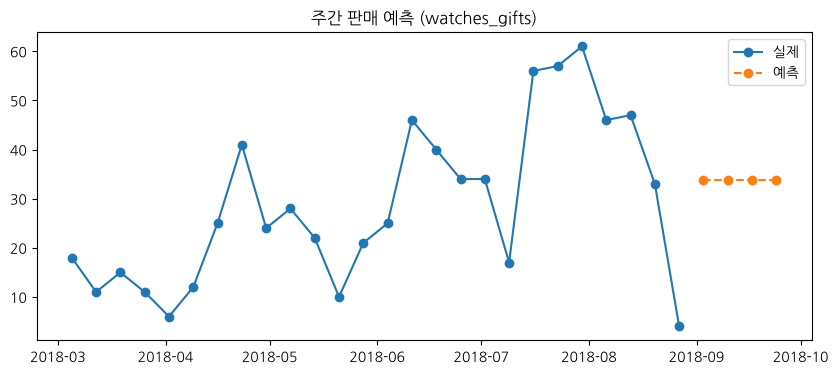

💬 '시계·선물' 카테고리는 다음 주부터 매주 약 34개씩 팔릴 것 같아요. 과거 8주로 맞춰보니 평균 ±18개 틀렸어요 (신뢰도: 높음).


In [2]:
r = st.call('demand_forecast', {'seller_id': BIG})
show(r)
st.plot('plot_forecast', seller_id=BIG); plt.show()
ko = st.daily.drop_duplicates('category_en').set_index('category_en').category_ko
print('💬', f"'{ko.get(r['category'], r['category'])}' 카테고리는 다음 주부터 매주 약 {r['weekly_base']:.0f}개씩 팔릴 것 같아요. 과거 8주로 맞춰보니 평균 ±{r['backtest_mae_8w']:.0f}개 틀렸어요 (신뢰도: {r['confidence']}).")

## 4-2. 이벤트 반영 + 과거 시점 재현
`as_of`로 과거 시점에서 예측해 보고 실제와 비교할 수 있어요. 2018년 어머니날은 **2017년 어머니날 배수**를 써요.

In [3]:
def forecast_vs_actual(sid, as_of):
    r = st.demand_forecast(sid, as_of=as_of)
    act = st.weekly[(st.weekly.seller_id == r['seller_id']) & (st.weekly.category_en == r['category'])].set_index('week_start').units
    f = pd.DataFrame(r['forecast'])
    f['actual_units'] = [act.get(pd.Timestamp(w), np.nan) for w in f.week_start]
    return f[['week_start', 'forecast_units', 'actual_units', 'event', 'event_multiple', 'event_multiple_basis']]
print('2018년 어머니날 직전 시점'); print(forecast_vs_actual(BIG, '2018-04-30'))
print('\n2017년 블랙프라이데이 직전 시점 (지난해 기록이 없어서 그해 배수를 참고용으로 씀)'); print(forecast_vs_actual(BIG, '2017-11-06'))

2018년 어머니날 직전 시점


  week_start  forecast_units  actual_units event  event_multiple  \
0 2018-05-07            35.1          28.0  어머니날            1.62   
1 2018-05-14            21.7          22.0   NaN            1.00   
2 2018-05-21            21.7          10.0   NaN            1.00   
3 2018-05-28            21.7          21.0   NaN            1.00   

  event_multiple_basis  
0         2017년 같은 이벤트  
1                  NaN  
2                  NaN  
3                  NaN  

2017년 블랙프라이데이 직전 시점 (지난해 기록이 없어서 그해 배수를 참고용으로 씀)


  week_start  forecast_units  actual_units    event  event_multiple  \
0 2017-11-13            24.4          40.0      NaN            1.00   
1 2017-11-20            38.8          45.0  블랙프라이데이            1.59   
2 2017-11-27            29.2          24.0  블랙프라이데이            1.20   
3 2017-12-04            24.4          26.0      NaN            1.00   

            event_multiple_basis  
0                            NaN  
1  2017년 같은 이벤트 (지난해 기록 없음, 참고용)  
2  2017년 같은 이벤트 (지난해 기록 없음, 참고용)  
3                            NaN  


## 4-3. 발주량 계산 + 품절 위험 조정
**발주량 = 입고 기간 동안 예상 수요 + 안전재고 − 현재 재고**. 안전재고는 수요가 들쭉날쭉한 정도(최근 12주 표준편차)와 목표 서비스 수준(품절 안 날 확률)으로 정해요.

In [4]:
r = st.call('reorder_quantity', {'seller_id': BIG, 'current_stock': 20, 'lead_time_weeks': 2})
show(r)
print('💬', f"입고까지 {r['lead_time_weeks']}주 동안 약 {r['demand_during_lead_time']:.0f}개가 팔리고, 품절 위험을 {1 - r['service_level']:.0%}로 막으려면 안전재고 {r['safety_stock']:.0f}개가 필요해요. "
      f"지금 재고 {r['current_stock']}개를 빼면 {r['order_quantity']}개를 주문하세요.")

{
 "seller_id": "6560211a19b47992c3666cc44a7e94c0",
 "category": "watches_gifts",
 "lead_time_weeks": 2,
 "current_stock": 20,
 "demand_during_lead_time": 67.8,
 "safety_stock": 38.7,
 "service_level": 0.95,
 "order_quantity": 87,
 "forecast": [
  {
   "week_start": "2018-09-03",
   "forecast_units": 33.9,
   "event": null,
   "event_multiple": 1.0,
   "event_multiple_basis": null
  },
  {
   "week_start": "2018-09-10",
   "forecast_units": 33.9,
   "event": null,
   "event_multiple": 1.0,
   "event_multiple_basis": null
  }
 ],
 "confidence": "높음",
 "backtest_mae_8w": 17.6469,
 "note": "입고 기간과 현재 재고는 데이터에 없어서 판매자가 입력한 값이에요."
}
💬 입고까지 2주 동안 약 68개가 팔리고, 품절 위험을 5%로 막으려면 안전재고 39개가 필요해요. 지금 재고 20개를 빼면 87개를 주문하세요.


In [5]:
rows = []
for sl in [0.80, 0.90, 0.95, 0.99]:
    r = st.call('reorder_quantity', {'seller_id': BIG, 'current_stock': 20, 'lead_time_weeks': 2, 'service_level': sl})
    rows.append({'품절 안 날 확률 목표': f'{sl:.0%}', '안전재고': r['safety_stock'], '발주량': r['order_quantity']})
pd.DataFrame(rows)

,품절 안 날 확률 목표,안전재고,발주량
0,80%,19.8,68
1,90%,30.2,78
2,95%,38.7,87
3,99%,54.8,103


## 4-4. 발주 우선순위 (여러 카테고리를 파는 판매자)
재고를 주면 **남은 주 수(재고 ÷ 주간 예측)가 짧은 순**, 안 주면 발주량이 큰 순으로 정렬해요.

In [6]:
r = st.call('reorder_priority', {'seller_id': BIG, 'lead_time_weeks': 2})
print(pd.DataFrame(r['priorities']))
r2 = st.call('reorder_priority', {'seller_id': BIG, 'lead_time_weeks': 2, 'stock': {'watches_gifts': 40, 'fashion_bags_accessories': 2}})
print('\n재고를 알려줬을 때'); print(pd.DataFrame(r2['priorities']))
p = r2['priorities'][0]
print('\n💬', f"가장 먼저 '{p['category_ko']}' 카테고리를 주문하세요. 지금 재고로는 {p['weeks_of_cover']}주밖에 못 버텨서 입고 전에 떨어져요. {p['order_quantity']}개가 필요해요.")

                category_en category_ko  current_stock  weekly_forecast  \
0             watches_gifts       시계·선물              0             33.9   
1  fashion_bags_accessories     가방·액세서리              0              5.0   
2                 perfumery          향수              0              0.1   
3     computers_accessories    컴퓨터 액세서리              0              0.1   
4                     audio         오디오              0              0.0   
5            sports_leisure      스포츠·레저              0              0.0   

   weeks_of_cover  order_quantity confidence  runs_out_before_restock  
0             0.0             107         높음                     True  
1             0.0              21         높음                     True  
2             0.0               3         낮음                     True  
3             0.0               2         낮음                     True  
4             NaN               0         낮음                    False  
5             NaN               0         


재고를 알려줬을 때
                category_en category_ko  current_stock  weekly_forecast  \
0             watches_gifts       시계·선물             40             33.9   
1  fashion_bags_accessories     가방·액세서리              2              5.0   
2                 perfumery          향수              0              0.1   
3     computers_accessories    컴퓨터 액세서리              0              0.1   
4                     audio         오디오              0              0.0   
5            sports_leisure      스포츠·레저              0              0.0   

   weeks_of_cover  order_quantity confidence  runs_out_before_restock  
0             1.2              67         높음                     True  
1             0.4              19         높음                     True  
2             0.0               3         낮음                     True  
3             0.0               2         낮음                     True  
4             NaN               0         낮음                    False  
5             NaN             

## 4-5. 이벤트 배수 표 (전처리 2판 `event_multiples`)

In [7]:
if st.evm_table is not None:
    t = st.evm_table[st.evm_table.category_en == '__all__'].pivot_table(index='event_ko', columns='year', values='multiple').round(2)
    print('시장 전체 이벤트 배수'); print(t)
    cat = st.ss.loc[BIG].main_category_en
    print(f'\n{cat} 카테고리 이벤트 배수'); print(st.evm_table[st.evm_table.category_en == cat].pivot_table(index='event_ko', columns='year', values='multiple').round(2))

시장 전체 이벤트 배수
year         2017  2018
event_ko               
블랙프라이데이      3.70   NaN
아버지날         0.96  1.28
어머니날         1.31  1.16
연인의 날(6/12)  1.01  1.19
크리스마스        0.72   NaN

watches_gifts 카테고리 이벤트 배수
year         2017  2018
event_ko               
블랙프라이데이      2.38   NaN
아버지날         0.92  1.00
어머니날         1.62  1.52
연인의 날(6/12)  1.10  1.29
크리스마스        0.89   NaN
